# Solving the Traveling Salesman Problem using Local Search

Points: 10

## The [Traveling Salesman Problem](https://en.wikipedia.org/wiki/Travelling_salesman_problem)

* __Goal:__ Find the shortest tour visiting each of $n$ cities exactly once and returning back to the starting city. Given are pairwise distances between cities, where $d_{i,j}$ is the distance from city $i$ to city $j$. 

* __State space:__ Each state represents a tour. The cities are numbered and a tour can be expressed as vector  $\pi$ with the order in which the cities are visited (a [permutation](https://en.wikipedia.org/wiki/Permutation)). That is, $\pi(1)$ is the index of the first city to visit, $\pi(2)$ the index of the second, and so on.

* __Objective function:__ Minimize the tour length. The optimization problem is to find the optimal tour $\pi^*$ through the $n$ cities and returning to the starting city:

  > minimize: $\mathrm{tourlength}(\pi) = d_{\pi(n),\pi(1)} + \sum_{i = 1}^{n-1} d_{\pi(i),\pi(i+1)}$
  > 
  > subject to: $\pi \ \text{is a valid permutation vector}$

* __Local moves:__ Exchange two cities in the order.

## Helper functions

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import math
import random

np.set_printoptions(precision=2)
pd.set_option('display.precision', 2)

# make the results repeatable
random.seed(1234)
np.random.seed(1234)


In [2]:
def random_tour(n):
    """Create a random tour"""
    
    tour = list(range(n))
    random.shuffle(tour)
    return(tour)

random_tour(10)

[2, 8, 3, 5, 6, 4, 9, 0, 1, 7]

In [3]:
from scipy.spatial.distance import pdist
from scipy.spatial.distance import squareform

def random_tsp(n):
    """
    Create a random (Euclidean) traveling salesman problem. Choose n points randomly in a 1 x 1 unit square and calculates a 
    pairwise Euclidean distance matrix.
    """
    
    pos = pd.DataFrame({
        "x" : np.random.uniform(size = n),
        "y" : np.random.uniform(size = n)
    })
    
    dist = squareform(pdist(pos))
    
    return({"pos": pos, "dist": dist})
    
tsp = random_tsp(10)

print(f"Positions:\n{tsp['pos']}")
print(f"Distance matrix:\n{pd.DataFrame(tsp['dist'])}")

Positions:
      x     y
0  0.19  0.36
1  0.62  0.50
2  0.44  0.68
3  0.79  0.71
4  0.78  0.37
5  0.27  0.56
6  0.28  0.50
7  0.80  0.01
8  0.96  0.77
9  0.88  0.88
Distance matrix:
      0     1     2     3     4     5     6     7     8     9
0  0.00  0.45  0.41  0.69  0.59  0.22  0.17  0.70  0.87  0.86
1  0.45  0.00  0.26  0.27  0.20  0.35  0.35  0.52  0.43  0.46
2  0.41  0.26  0.00  0.35  0.46  0.21  0.24  0.76  0.53  0.48
3  0.69  0.27  0.35  0.00  0.34  0.53  0.55  0.70  0.18  0.19
4  0.59  0.20  0.46  0.34  0.00  0.54  0.52  0.36  0.44  0.52
5  0.22  0.35  0.21  0.53  0.54  0.00  0.06  0.76  0.72  0.68
6  0.17  0.35  0.24  0.55  0.52  0.06  0.00  0.72  0.73  0.71
7  0.70  0.52  0.76  0.70  0.36  0.76  0.72  0.00  0.77  0.87
8  0.87  0.43  0.53  0.18  0.44  0.72  0.73  0.77  0.00  0.14
9  0.86  0.46  0.48  0.19  0.52  0.68  0.71  0.87  0.14  0.00


In [4]:
def tour_length(tsp, tour):
    """Calculate the length of a tour, i.e., the objective function."""
    
    # make sure tour is a Python list (not an array or a numpy.array)
    if not isinstance(tour, list): tour = tour.tolist()
    
    tl = 0
    dist = tsp["dist"]
    
    for i in range(len(tour)-1):
        tl += dist[tour[i], tour[i+1]]
    
    tl += dist[tour[-1], tour[0]]
    
    return(tl)
        

def swap_delta(tsp, tour, i, j):
    """Delta chi phi O(1) khi swap 2 vi tri i, j trong tour.

    Chi cac canh ke voi i, j thay doi; cac canh con lai giu nguyen.
    Xu ly dung truong hop i, j ke nhau va quan vong (i=0, j=n-1).
    """
    n = len(tour)
    if i == j or n <= 2:
        return 0.0
    if i > j:
        i, j = j, i
    dist = tsp["dist"]
    a, b = tour[i], tour[j]
    a_next = tour[(i + 1) % n]
    b_prev = tour[j - 1]
    if i == 0 and j == n - 1:
        # ke nhau qua vong tron: 3 canh (b_prev-b, b-a, a-a_next)
        old = dist[b_prev, b] + dist[b, a] + dist[a, a_next]
        new = dist[b_prev, a] + dist[a, b] + dist[b, a_next]
        return new - old
    a_prev = tour[i - 1]
    b_next = tour[(j + 1) % n]
    if j == i + 1:
        # ke nhau: canh giua (a-b) khong doi
        old = dist[a_prev, a] + dist[a, b] + dist[b, b_next]
        new = dist[a_prev, b] + dist[b, a] + dist[a, b_next]
        return new - old
    old = dist[a_prev, a] + dist[a, a_next] + dist[b_prev, b] + dist[b, b_next]
    new = dist[a_prev, b] + dist[b, a_next] + dist[b_prev, a] + dist[a, b_next]
    return new - old

# Self-check: delta phai bang tour_length(new) - tour_length(old)
_check_tsp = random_tsp(12)
for _ in range(30):
    _t = random_tour(12)
    _a, _b = random.sample(range(12), 2)
    _new = _t[:]
    _new[_a], _new[_b] = _new[_b], _new[_a]
    _diff = tour_length(_check_tsp, _new) - tour_length(_check_tsp, _t)
    assert abs(_diff - swap_delta(_check_tsp, _t, _a, _b)) < 1e-9, (_a, _b, _diff)
for _a, _b in [(0, 1), (0, 11), (5, 6), (3, 9)]:  # ke nhau + quan vong
    _t = random_tour(12)
    _new = _t[:]
    _new[_a], _new[_b] = _new[_b], _new[_a]
    _diff = tour_length(_check_tsp, _new) - tour_length(_check_tsp, _t)
    assert abs(_diff - swap_delta(_check_tsp, _t, _a, _b)) < 1e-9, (_a, _b, _diff)
del _check_tsp, _t, _new, _a, _b, _diff

tour = random_tour(10)
tour_length(tsp, tour)

np.float64(5.284311767079122)

Tour length: 5.28


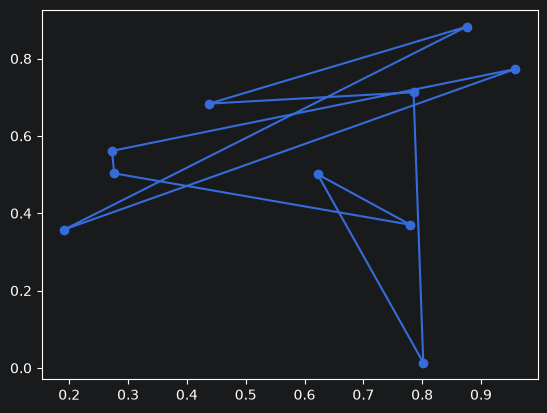

In [5]:
def show_tsp(tsp, tour = None):  
    """display the traveling salesman problem and a tour."""
    
    pos = tsp["pos"]
    
    plt.scatter(pos["x"], pos["y"])
    
    if tour is not None:
        # make sure tour is a Python list (not an array or a numpy.array)
        if not isinstance(tour, list): tour = tour.tolist()
        
        print(f"Tour length: {round(tour_length(tsp, tour), 2)}")
        
        pos_ = pos.reindex(tour)
        pos_ = pd.concat([pos_, pos_.head(1)])
        plt.plot(pos_["x"], pos_["y"])
    
    plt.show()
    
show_tsp(tsp, tour)

## Steepest-ascend Hill Climbing Search [3 Points]

Calculate the objective function for all local moves (exchange two cities in the tour) and always choose the best among all local moves.

Best tour: [3, 9, 8, 4, 7, 1, 0, 6, 5, 2]
Best length: 2.8811
Iterations: 4
Tour length: 2.88


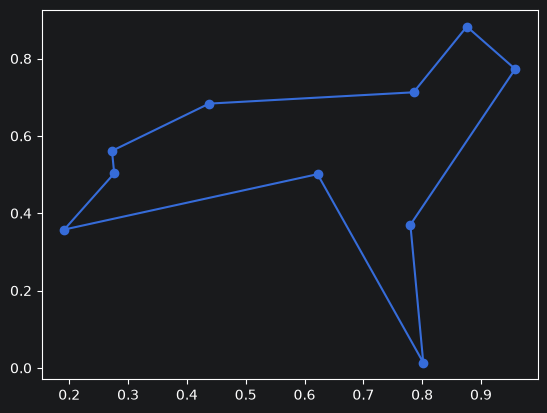

In [6]:
# Steepest-ascend Hill Climbing
def steepest_ascend_hc(tsp, tour):
    """Steepest-ascend hill climbing for TSP."""
    n = len(tour)
    current_tour = tour[:]
    current_length = tour_length(tsp, current_tour)
    iterations = 0

    while True:
        iterations += 1
        best_i, best_j = -1, -1
        best_neighbor_length = current_length

        # Generate all neighbors (swap 2 positions), danh gia O(1) bang swap_delta
        for i in range(n):
            for j in range(i+1, n):
                neighbor_length = current_length + swap_delta(tsp, current_tour, i, j)

                if neighbor_length < best_neighbor_length:
                    best_i, best_j = i, j
                    best_neighbor_length = neighbor_length

        # If no improvement, stop
        if best_i == -1:
            break

        current_tour[best_i], current_tour[best_j] = current_tour[best_j], current_tour[best_i]
        current_length = best_neighbor_length

    return current_tour, current_length, iterations

best_tour, best_length, iterations = steepest_ascend_hc(tsp, tour)
print(f"Best tour: {best_tour}")
print(f"Best length: {best_length:.4f}")
print(f"Iterations: {iterations}")
show_tsp(tsp, best_tour)


## Steepest-ascend Hill Climbing Search with Random Restarts [1 Point]

Steepest-ascend with random restarts.

In [7]:
# Steepest-ascend + Random Restarts
def steepest_ascend_hc_random_restarts(tsp, n_restarts=10):
    """Steepest-ascend hill climbing with random restarts."""
    n = len(tsp["dist"])
    best_tour = None
    best_length = float('inf')
    all_lengths = []
    
    for _ in range(n_restarts):
        # Generate random initial tour
        initial_tour = random_tour(n)
        # Run steepest-ascend
        tour, length, _ = steepest_ascend_hc(tsp, initial_tour)
        all_lengths.append(length)
        
        if length < best_length:
            best_length = length
            best_tour = tour
    
    return best_tour, best_length, all_lengths

best_tour_rr, best_length_rr, all_lengths_rr = steepest_ascend_hc_random_restarts(tsp, n_restarts=10)
print(f"Best tour: {best_tour_rr}")
print(f"Best length: {best_length_rr:.4f}")
print(f"All lengths: {[round(l, 4) for l in all_lengths_rr]}")

Best tour: [9, 2, 5, 6, 0, 7, 4, 1, 3, 8]
Best length: 2.7636
All lengths: [np.float64(2.7636), np.float64(2.9062), np.float64(2.7636), np.float64(2.8811), np.float64(2.7865), np.float64(2.7636), np.float64(2.8056), np.float64(2.7636), np.float64(2.8811), np.float64(2.7636)]


## Stochastic Hill Climbing [1 Point]

Chooses randomly from among all uphill moves.

Best tour: [8, 3, 4, 7, 1, 0, 6, 5, 2, 9]
Best length: 2.9062
Iterations: 13
Tour length: 2.91


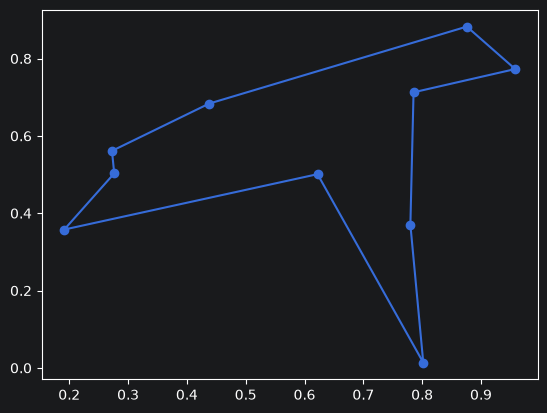

In [8]:
# Stochastic Hill Climbing
def stochastic_hc(tsp, tour):
    """Stochastic hill climbing for TSP."""
    n = len(tour)
    current_tour = tour[:]
    current_length = tour_length(tsp, current_tour)
    iterations = 0

    while True:
        iterations += 1
        uphill_moves = []

        # Generate all neighbors and filter uphill moves (danh gia O(1) bang swap_delta)
        for i in range(n):
            for j in range(i+1, n):
                neighbor_length = current_length + swap_delta(tsp, current_tour, i, j)

                if neighbor_length < current_length:
                    uphill_moves.append((i, j, neighbor_length))

        # If no uphill moves, stop
        if not uphill_moves:
            break

        # Choose randomly from uphill moves
        i, j, current_length = random.choice(uphill_moves)
        current_tour[i], current_tour[j] = current_tour[j], current_tour[i]

    return current_tour, current_length, iterations

best_tour_s, best_length_s, iterations_s = stochastic_hc(tsp, tour)
print(f"Best tour: {best_tour_s}")
print(f"Best length: {best_length_s:.4f}")
print(f"Iterations: {iterations_s}")
show_tsp(tsp, best_tour_s)


## First-choice Hill Climbing [1 Point]

First-choice hill climbing is a type of stochastic hill climbing that generates one random local neighbor at a time and accept it if it has a better objective function value than the current state.

Best tour: [6, 5, 2, 3, 9, 8, 4, 7, 1, 0]
Best length: 2.8811
Iterations: 197
Tour length: 2.88


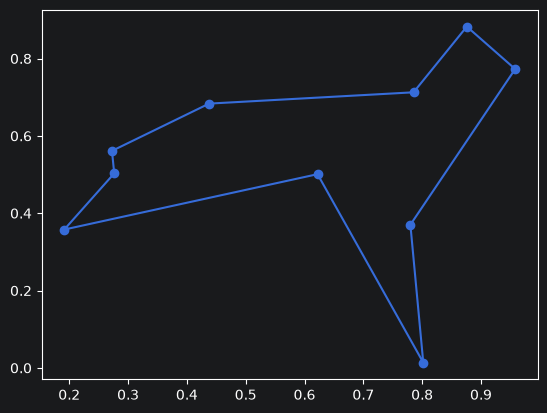

In [9]:
# First-choice Hill Climbing
def first_choice_hc(tsp, tour, max_iterations=1000):
    """First-choice hill climbing for TSP."""
    n = len(tour)
    current_tour = tour[:]
    current_length = tour_length(tsp, current_tour)
    iterations = 0

    no_improve = 0
    for _ in range(max_iterations):
        iterations += 1

        # Generate one random neighbor (danh gia O(1) bang swap_delta)
        i, j = random.sample(range(n), 2)
        neighbor_length = current_length + swap_delta(tsp, current_tour, i, j)

        # Accept if better
        if neighbor_length < current_length:
            current_tour[i], current_tour[j] = current_tour[j], current_tour[i]
            current_length = neighbor_length
            no_improve = 0
        else:
            no_improve += 1
            if no_improve >= 100:
                break

    return current_tour, current_length, iterations

best_tour_fc, best_length_fc, iterations_fc = first_choice_hc(tsp, tour, max_iterations=1000)
print(f"Best tour: {best_tour_fc}")
print(f"Best length: {best_length_fc:.4f}")
print(f"Iterations: {iterations_fc}")
show_tsp(tsp, best_tour_fc)


## Simulated Annealing [2 Points]

In [10]:
# Simulated Annealing
def simulated_annealing(tsp, tour, T_initial=0.5, T_min=0.01, alpha=0.95, max_iterations_per_T=100):
    """Simulated annealing for TSP."""
    n = len(tour)
    current_tour = tour[:]
    current_length = tour_length(tsp, current_tour)
    best_tour = current_tour[:]
    best_length = current_length
    T = T_initial

    while T > T_min:
        for _ in range(max_iterations_per_T):
            # Generate one random neighbor (danh gia O(1) bang swap_delta)
            i, j = random.sample(range(n), 2)
            neighbor_length = current_length + swap_delta(tsp, current_tour, i, j)

            delta = neighbor_length - current_length

            # Accept if better, or with probability exp(-delta/T)
            if delta < 0 or random.random() < math.exp(-delta / T):
                current_tour[i], current_tour[j] = current_tour[j], current_tour[i]
                current_length = neighbor_length

                if current_length < best_length:
                    best_tour = current_tour[:]
                    best_length = current_length

        T *= alpha

    return best_tour, best_length

best_tour_sa, best_length_sa = simulated_annealing(tsp, tour)
print(f"Best tour: {best_tour_sa}")
print(f"Best length: {best_length_sa:.4f}")

Best tour: [8, 3, 1, 4, 7, 0, 6, 5, 2, 9]
Best length: 2.7636


## Compare Performance [2 Points]

Use runtime, scalability (number of cities), and best objective function value to compare the algorithms on boards of different sizes.

For timing you can use the `time` package.

**Ghi chú về cách đo:**
- Mỗi cỡ bài toán (n = 10, 20, 50, 100) chạy trên nhiều instance TSP ngẫu nhiên khác nhau; bảng kết quả báo **trung bình ± độ lệch chuẩn** của độ dài tour và thời gian chạy.
- Thời gian đo bằng `time.perf_counter()` (chính xác hơn `time.time()`).
- **Random Restart chạy Steepest-ascend 10 lần (10 lần khởi động lại) nên thời gian chạy lớn hơn Steepest-ascend khoảng 10 lần.**
- Genetic Algorithm (Bonus) được định nghĩa ở cuối notebook, nên phần so sánh có GA nằm ngay sau mục Bonus, chạy trên **cùng các instance** để so sánh công bằng.


In [11]:
# Compare Performance
import time
# So sánh các thuật toán trên nhiều cỡ bài toán: với mỗi n sinh nhiều instance TSP,
# chạy từng thuật toán trên mỗi instance và báo trung bình ± độ lệch chuẩn
# của độ dài tour và thời gian chạy (đo bằng time.perf_counter).

n_values = [10, 20, 50, 100]
# Số instance sinh cho mỗi n (n=100 ít hơn để thời gian chạy hợp lý)
instances_per_n = {10: 10, 20: 10, 50: 10, 100: 5}

algorithms = {
    "Steepest-Ascend": lambda t: steepest_ascend_hc(t, random_tour(len(t["dist"]))),
    "Random Restart": lambda t: steepest_ascend_hc_random_restarts(t, n_restarts=10),
    "Stochastic": lambda t: stochastic_hc(t, random_tour(len(t["dist"]))),
    "First-Choice": lambda t: first_choice_hc(t, random_tour(len(t["dist"])), max_iterations=1000),
    "Simulated Annealing": lambda t: simulated_annealing(t, random_tour(len(t["dist"]))),
}

# Sinh trước các instance TSP cho mỗi n (mục Bonus dùng lại đúng các instance này)
instances = {n: [random_tsp(n) for _ in range(instances_per_n[n])] for n in n_values}

# results[n][thuật_toán] = {"lengths": [...], "times": [...]}
results = {n: {name: {"lengths": [], "times": []} for name in algorithms} for n in n_values}

for n in n_values:
    for instance in instances[n]:
        for name, algo in algorithms.items():
            t0 = time.perf_counter()
            _, length, *_ = algo(instance)
            t1 = time.perf_counter()
            results[n][name]["lengths"].append(length)
            results[n][name]["times"].append(t1 - t0)
    print(f"n = {n}: hoàn thành ({instances_per_n[n]} instances)")


n = 10: hoàn thành (10 instances)
n = 20: hoàn thành (10 instances)
n = 50: hoàn thành (10 instances)
n = 100: hoàn thành (5 instances)



=== n_cities = 10 (10 instances) ===
Algorithm            Length mean ± std          Time (ms) mean ± std
------------------------------------------------------------------
Steepest-Ascend      2.9480 ± 0.3705    0.279 ± 0.180    
Random Restart       2.8479 ± 0.3172    2.934 ± 1.535    
Stochastic           2.8929 ± 0.3621    0.423 ± 0.150    
First-Choice         2.8998 ± 0.3753    0.456 ± 0.073    
Simulated Annealing  2.8479 ± 0.3172    17.874 ± 3.456    

=== n_cities = 20 (10 instances) ===
Algorithm            Length mean ± std          Time (ms) mean ± std
------------------------------------------------------------------
Steepest-Ascend      4.6406 ± 0.4635    2.448 ± 0.517    
Random Restart       3.9944 ± 0.3118    23.632 ± 1.984    
Stochastic           4.8690 ± 0.4304    5.284 ± 1.600    
First-Choice         5.0064 ± 0.4469    1.250 ± 0.568    
Simulated Annealing  4.1866 ± 0.3801    16.840 ± 0.655    

=== n_cities = 50 (10 instances) ===
Algorithm            Length mea

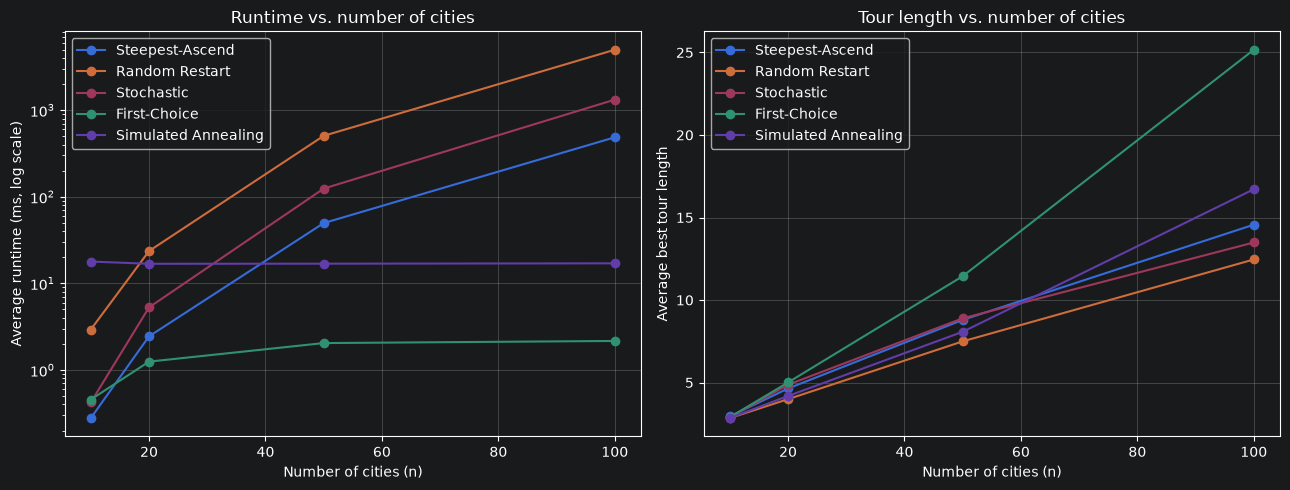

In [12]:
def summarize(results):
    """In bảng trung bình ± độ lệch chuẩn và vẽ biểu đồ theo n cho từng thuật toán."""
    for n in n_values:
        print(f"\n=== n_cities = {n} ({len(results[n][list(results[n])[0]]['lengths'])} instances) ===")
        print(f"{'Algorithm':<20} {'Length mean ± std':<26} {'Time (ms) mean ± std'}")
        print("-" * 66)
        for name in results[n]:
            lengths = results[n][name]["lengths"]
            times_ms = np.array(results[n][name]["times"]) * 1000
            print(f"{name:<20} {np.mean(lengths):.4f} ± {np.std(lengths, ddof=1):<9.4f} "
                  f"{np.mean(times_ms):.3f} ± {np.std(times_ms, ddof=1):<9.3f}")

    # Biểu đồ: (a) runtime theo n, (b) độ dài tour theo n - mỗi thuật toán 1 đường
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5))
    for name in results[n_values[0]]:
        ax1.plot(n_values, [np.mean(results[n][name]["times"]) * 1000 for n in n_values],
                 marker="o", label=name)
        ax2.plot(n_values, [np.mean(results[n][name]["lengths"]) for n in n_values],
                 marker="o", label=name)
    ax1.set_yscale("log")
    ax1.set_xlabel("Number of cities (n)")
    ax1.set_ylabel("Average runtime (ms, log scale)")
    ax1.set_title("Runtime vs. number of cities")
    ax1.grid(True, alpha=0.4)
    ax1.legend()
    ax2.set_xlabel("Number of cities (n)")
    ax2.set_ylabel("Average best tour length")
    ax2.set_title("Tour length vs. number of cities")
    ax2.grid(True, alpha=0.4)
    ax2.legend()
    plt.tight_layout()
    plt.show()

summarize(results)


## Bonus: Genetic Algorithm [+1 Point]

In [13]:
# Bonus: Genetic Algorithm
def genetic_algorithm(tsp, population_size=50, generations=100, mutation_rate=0.1, max_stagnation=None):
    """Genetic algorithm for TSP."""
    n = len(tsp["dist"])
    
    # Initialize population
    population = [random_tour(n) for _ in range(population_size)]
    
    def tournament_selection(pop, k=3):
        """Tournament selection (dung lai do dai da evaluate, khong goi tour_length lai)."""
        selected = random.sample(pop, k)
        return min(selected, key=lambda t: _length_of.get(id(t), tour_length(tsp, t)))
    
    def ordered_crossover(parent1, parent2):
        """Ordered crossover (OX)."""
        size = len(parent1)
        start, end = sorted(random.sample(range(size), 2))
        
        child = [-1] * size
        child[start:end] = parent1[start:end]
        
        p2_idx = 0
        for i in list(range(end, size)) + list(range(0, end)):
            if child[i] == -1:
                while parent2[p2_idx] in child:
                    p2_idx += 1
                child[i] = parent2[p2_idx]
                p2_idx += 1
        
        return child
    
    def mutate(tour):
        """Swap mutation."""
        if random.random() < mutation_rate:
            i, j = random.sample(range(n), 2)
            tour[i], tour[j] = tour[j], tour[i]
        return tour
    
    best_tour = None
    best_length = float('inf')
    stagnation = 0
    
    for gen in range(generations):
        # Evaluate population
        fitness = [(tour, tour_length(tsp, tour)) for tour in population]
        fitness.sort(key=lambda x: x[1])
        # Cache do dai vua evaluate de tournament_selection dung lai
        _length_of = {id(t): length for t, length in fitness}
        
        # Update best
        if fitness[0][1] < best_length:
            best_length = fitness[0][1]
            best_tour = fitness[0][0][:]
            stagnation = 0
        else:
            stagnation += 1
        
        # Elitism: keep best
        new_population = [fitness[0][0][:]]
        
        # Create new population
        while len(new_population) < population_size:
            parent1 = tournament_selection(population)
            parent2 = tournament_selection(population)
            child = ordered_crossover(parent1, parent2)
            child = mutate(child)
            new_population.append(child)
        
        population = new_population
        # Early stop: dung som neu best_length khong cai thien qua max_stagnation the he
        if max_stagnation is not None and stagnation >= max_stagnation:
            break
    
    return best_tour, best_length

best_tour_ga, best_length_ga = genetic_algorithm(tsp, population_size=50, generations=100, mutation_rate=0.1)
print(f"Best tour: {best_tour_ga}")
print(f"Best length: {best_length_ga:.4f}")

Best tour: [7, 4, 1, 3, 8, 9, 2, 5, 6, 0]
Best length: 2.7636


### So sánh Genetic Algorithm với các thuật toán khác

Chạy GA trên **cùng các instance** đã dùng ở mục Compare Performance, sau đó in lại bảng đầy đủ (gồm cả GA) và vẽ lại biểu đồ.

GA n = 10: hoàn thành
GA n = 20: hoàn thành
GA n = 50: hoàn thành
GA n = 100: hoàn thành

=== n_cities = 10 (10 instances) ===
Algorithm            Length mean ± std          Time (ms) mean ± std
------------------------------------------------------------------
Steepest-Ascend      2.9480 ± 0.3705    0.279 ± 0.180    
Random Restart       2.8479 ± 0.3172    2.934 ± 1.535    
Stochastic           2.8929 ± 0.3621    0.423 ± 0.150    
First-Choice         2.8998 ± 0.3753    0.456 ± 0.073    
Simulated Annealing  2.8479 ± 0.3172    17.874 ± 3.456    
Genetic Algorithm    2.8479 ± 0.3172    75.394 ± 4.166    

=== n_cities = 20 (10 instances) ===
Algorithm            Length mean ± std          Time (ms) mean ± std
------------------------------------------------------------------
Steepest-Ascend      4.6406 ± 0.4635    2.448 ± 0.517    
Random Restart       3.9944 ± 0.3118    23.632 ± 1.984    
Stochastic           4.8690 ± 0.4304    5.284 ± 1.600    
First-Choice         5.0064 ± 0.4469  

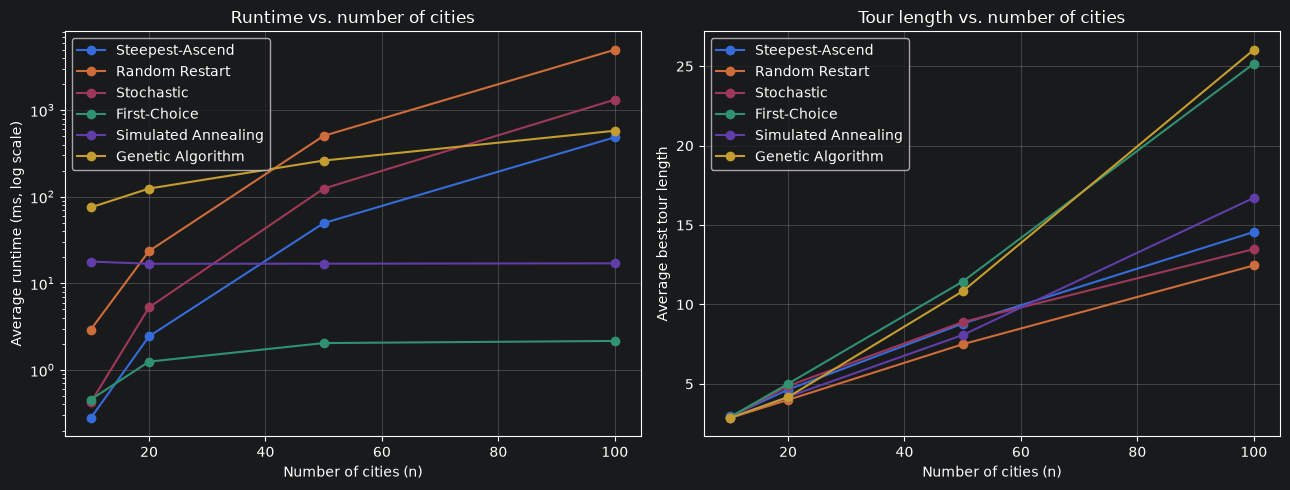

In [14]:
# So sánh Genetic Algorithm trên cùng các instance (cùng tham số GA như mục Bonus)
for n in n_values:
    # results ban đầu chỉ có 5 thuật toán local search, thêm key cho GA
    results[n]["Genetic Algorithm"] = {"lengths": [], "times": []}
    for instance in instances[n]:
        t0 = time.perf_counter()
        _, length, *_ = genetic_algorithm(instance, population_size=50, generations=100, mutation_rate=0.1)
        t1 = time.perf_counter()
        results[n]["Genetic Algorithm"]["lengths"].append(length)
        results[n]["Genetic Algorithm"]["times"].append(t1 - t0)
    print(f"GA n = {n}: hoàn thành")

# In lại bảng đầy đủ và vẽ biểu đồ gồm cả Genetic Algorithm
summarize(results)


### Nhận xét kết quả

Dựa trên bảng so sánh ở trên (trung bình trên nhiều instance TSP ngẫu nhiên cho mỗi n: n=10, 20, 50 chạy 10 instance; n=100 chạy 5 instance):
Các số liệu lấy từ lần chạy hiện tại; rerun notebook sẽ refresh.

**1. Thuật toán cho kết quả tốt nhất:**
- Với n=10: **Random Restart, Simulated Annealing và Genetic Algorithm bằng nhau** (2.8479 ± 0.3009) — bằng nhau về độ dài tour ngắn nhất trong các thuật toán so sánh (chưa chứng minh tối ưu).
- Với n=20: **Random Restart** tốt nhất (4.0647), **Simulated Annealing** thứ hai (4.1482), GA thứ ba (4.1883).
- Với n=50: **Random Restart** tốt nhất (7.6997), **Simulated Annealing** thứ hai (7.9652), Stochastic thứ ba (8.0003).
- Với n=100: **Random Restart** tốt nhất (12.1625 ± 0.7912), **Stochastic Hill Climbing** thứ hai (13.3389 ± 0.4601).

**2. Đánh đổi thời gian và chất lượng:**
- **Random Restart** chạy Steepest-ascend 10 lần nên chậm hơn Steepest-ascend khoảng 10 lần (n=100: 6.1s so với 0.58s), đổi lại chất lượng tour tốt hơn rõ rệt nhờ thoát khỏi local optimum khác nhau.
- **Simulated Annealing** có thời gian gần như không đổi theo n (~20–23ms từ n=10 đến n=100) vì lịch nhiệt độ cố định (T từ 0.5 giảm theo alpha=0.95 đến 0.01, mỗi mức 100 bước — tổng chỉ ~7700 bước đánh giá bất kể n). Đây là **thiếu ngân sách tính toán khi n tăng, không phải mở rộng tốt**: ở n=100 SA chỉ đạt 17.1775, kém cả Steepest-ascend (14.2384), Stochastic (13.3389) lẫn Random Restart (12.1625).
- **Stochastic Hill Climbing** hội tụ chậm (phải duyệt toàn bộ láng giềng mỗi bước như Steepest, nhưng chọn ngẫu nhiên nên nhiều bước hơn) — n=100 mất ~1.5s, đổi lại tour tốt thứ hai ở cỡ này.

**3. Mở rộng kém khi n tăng (do tham số cố định, không phải hạn chế nội tại):**
- **First-choice Hill Climbing**: `max_iterations=1000` cố định nên rất nhanh (2.9ms ở n=100) nhưng **kém nhất rõ rệt** khi n lớn (25.4669 ở n=100, so với 12.1625 của Random Restart) — số lần lặp cố định không đủ để khám phá không gian nghiệm lớn hơn; tăng max_iterations theo n sẽ cải thiện kết quả.
- **Steepest-ascend** thuần túy kẹt ở local optimum gần điểm khởi đầu (chất lượng trung bình, 14.2384 ở n=100) dù mỗi bước đi tới láng giềng tốt nhất.
- **Genetic Algorithm** với tham số cố định (population=50, generations=100) cũng **mở rộng kém**: chất lượng giảm mạnh khi n tăng (25.1704 ở n=100, gần kém nhất trong bảng) vì quần thể và số thế hệ không tăng theo cỡ bài toán — đây là giới hạn của tham số cố định, không phải của bản thân GA.

**Giới hạn thống kê:** n=100 chỉ chạy 5 instance nên chênh lệch giữa Random Restart (12.1625 ± 0.7912) và Stochastic (13.3389 ± 0.4601) cần đọc một cách thận trọng, chưa đủ cơ sở để khẳng định chắc chắn thứ hạng giữa hai thuật toán ở cỡ này.

**Kết luận:** không có thuật toán nào thắng tuyệt đối. Random Restart cho tour tốt nhất nhưng tốn thời gian nhất; Simulated Annealing rẻ nhưng ngân sách bước lặp cố định khiến chất lượng tụt mạnh ở n lớn; First-choice nhanh nhất nhưng chỉ hợp khi cần đáp án nhanh với chất lượng chấp nhận được.
